In [2]:
from pathlib import Path
import sys

project_root = next((p for p in (Path.cwd(), Path.cwd().parent) if (p / 'text_location_eval' / '__init__.py').is_file()), None)
if project_root is None:
    raise RuntimeError('Open this notebook from the project root or text_location_eval directory')
sys.path.insert(0, str(project_root))
from text_location_eval.inspect_results import inspect


In [ ]:
# Use None to automatically choose the most recently written retrieval.json.
RUN_DIR = "outputs/eval/text_location_eval/deepstreetsearchFULL-17bfc1d79410_1"  # e.g. 'outputs/eval/text_location_eval/deepstreetsearchFULL-abc123...'
QUERY_ID = 'Q024'
RANK = 1
SAVE_PATH = f'outputs/eval/text_location_eval/{QUERY_ID}.png'
# Q019, Q021, Q024


Query Q024: A narrow paved road between rice paddies, irrigation channels, scattered palm trees, and small houses.
Result #1 / 10 | Similarity: 0.2124
Coordinates: 14.817371, 120.789436
Map: https://www.openstreetmap.org/?mlat=14.81737087703655&mlon=120.7894359130635#map=15/14.81737087703655/120.7894359130635
Qwen holistic relevance: 3/3
Qwen summary: All requested features are visually present across the tiles: the narrow paved road, irrigation channels, scattered palm trees, and small houses. The scene is consistent with the query.
Category scores:
  landscape: 3/3 (importance 3) — All tiles show a narrow paved road running alongside water bodies consistent with irrigation channels or rice paddies, with distant land and structures suggesting paddies or farmland.
  vegetation: 3/3 (importance 3) — Scattered palm trees are visible in multiple tiles, especially in the lower half, standing near the water and road.
  focus_objects: 2/3 (importance 2) — Small houses or structures are visib

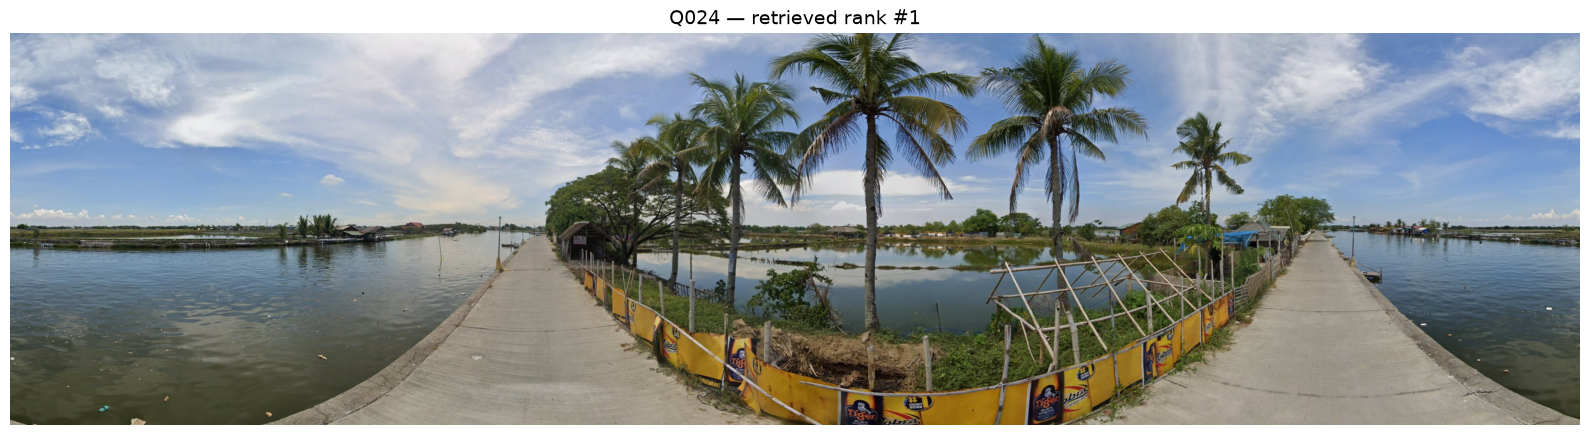

In [57]:
inspect(run_dir=RUN_DIR, query_id=QUERY_ID, rank=RANK, save_path=SAVE_PATH)


In [ ]:
CHECKPOINT = 'checkpoints/deepstreetsearchFULL.pt'  # Must match the saved index
GRID = 'outputs/grids/world.aggrid'  # Must match the saved index
SEARCH_DEVICE = 'auto'  # 'auto', 'cuda', or 'cpu'

import json
import ipywidgets as widgets
from IPython.display import display, clear_output
from text_location_eval.inspect_results import find_run_dir, original_panorama
from text_location_eval.indexing import load_index
from text_location_eval.common import file_sha256

_search_cache = {}

def _get_searcher():
    import torch
    import torch.nn.functional as F
    from transformers import AutoProcessor
    from adaptive_geogrid import load_grid
    from modules.model import GeoSearchModel

    run = find_run_dir(RUN_DIR)
    checkpoint = (project_root / CHECKPOINT).resolve()
    grid = (project_root / GRID).resolve()
    device = ('cuda' if torch.cuda.is_available() else 'cpu') if SEARCH_DEVICE == 'auto' else SEARCH_DEVICE
    cache_key = (str(run.resolve()), str(checkpoint), str(grid), device)
    if _search_cache.get('key') == cache_key:
        return _search_cache['value']

    with (run / 'retrieval.json').open(encoding='utf-8') as stream:
        retrieval = json.load(stream)
    index = load_index(run / 'reference.pt')
    signature = index['signature']
    if retrieval['index_signature'] != signature:
        raise ValueError('Reference index differs from the saved retrieval run')
    if file_sha256(checkpoint) != signature['checkpoint_sha256']:
        raise ValueError('CHECKPOINT does not match the checkpoint used to build reference.pt')
    if file_sha256(grid) != signature['grid_sha256']:
        raise ValueError('GRID does not match the grid used to build reference.pt')

    model = GeoSearchModel(load_grid(str(grid)), model_name=signature['model'])
    weights = torch.load(checkpoint, map_location='cpu', weights_only=True)
    model.load_state_dict(weights['model'])
    del weights
    model = model.to(device).eval()
    processor = AutoProcessor.from_pretrained(signature['model'])
    aggregation = retrieval['aggregation']
    with torch.inference_mode():
        views = F.normalize(index['embeddings'].float(), dim=-1)
        gallery = F.normalize(views.mean(dim=1), dim=-1) if aggregation == 'mean' else views
    result = dict(run=run, model=model, processor=processor, gallery=gallery,
                  records=index['records'], aggregation=aggregation, device=device, torch=torch, F=F)
    _search_cache.clear()
    _search_cache.update(key=cache_key, value=result)
    return result

def _on_custom_search(_):
    with custom_output:
        clear_output(wait=True)
        prompt = custom_prompt.value.strip()
        if not prompt:
            print('Enter a description first.')
            return
        custom_button.disabled = True
        try:
            searcher = _get_searcher()
            torch, F = searcher['torch'], searcher['F']
            tokenizer = searcher['processor'].tokenizer
            token_count = len(tokenizer([prompt], truncation=False, add_special_tokens=True)['input_ids'][0])
            limit = searcher['model'].backbone.config.text_config.max_position_embeddings
            if token_count > limit:
                raise ValueError(f'Prompt is {token_count} tokens; model limit is {limit}. Shorten it.')
            inputs = searcher['processor'](text=[prompt], padding='max_length',
                            truncation=True, return_tensors='pt')
            inputs = {k: v.to(searcher['device']) for k, v in inputs.items()
                      if k in {'input_ids', 'attention_mask'}}
            with torch.inference_mode():
                text = F.normalize(searcher['model'].encode_text(inputs).float(), dim=-1)[0].cpu()
                gallery = searcher['gallery']
                scores = (gallery @ text if searcher['aggregation'] == 'mean'
                          else torch.einsum('d,nvd->nv', text, gallery).amax(dim=-1))
                k = min(10, len(searcher['records']))
                values, ids = scores.topk(k)
            rank = custom_rank.value
            if rank > k:
                raise ValueError(f'Index contains only {k} selectable ranks')
            record = searcher['records'][ids[rank - 1].item()]
            print(f'Prompt: {prompt}')
            print(f'Result #{rank} / {k} | Similarity: {values[rank - 1].item():.4f}')
            print(f"Coordinates: {record['latitude']:.6f}, {record['longitude']:.6f}")
            print('Map: https://www.openstreetmap.org/'
                  f"?mlat={record['latitude']}&mlon={record['longitude']}"
                  f"#map=15/{record['latitude']}/{record['longitude']}")
            print('No Qwen evaluation was performed.')
            from PIL import Image
            import matplotlib.pyplot as plt
            path = original_panorama(searcher['run'], record)
            fig, ax = plt.subplots(figsize=(16, 8))
            with Image.open(path) as image:
                ax.imshow(image)
            ax.axis('off')
            ax.set_title(f'Custom query — rank #{rank}')
            plt.show()
            plt.close(fig)
        except Exception as exc:
            print(f'Search failed: {exc}')
        finally:
            custom_button.disabled = False

custom_prompt = widgets.Textarea(placeholder='Describe the location you want to find...',
                                 layout=widgets.Layout(width='100%', height='100px'))
custom_rank = widgets.BoundedIntText(value=1, min=1, max=10, description='Rank')
custom_button = widgets.Button(description='Search', button_style='primary')
custom_output = widgets.Output()
custom_button.on_click(_on_custom_search)
display(widgets.VBox([custom_prompt, widgets.HBox([custom_rank, custom_button]), custom_output]))
